# Customer Churn Prediction in Telecom
### End-to-End Classification with Class Imbalance, SMOTE, & Precision-Recall Threshold Tuning

**Tech Stack:** `Python` • `Pandas` • `Scikit-Learn` • `Imbalanced-Learn` • `Matplotlib` • `Seaborn`

---
### Project Highlights & Resume Alignment
1. **Dataset**: Telecom customer data covering customer usage patterns, contract type, internet services, and billing info.
2. **Class Imbalance Handling**: Applied **SMOTE** (Synthetic Minority Over-sampling Technique) strictly to the training partition to balance churners vs non-churners without data leakage.
3. **Model Development**: Trained a linear baseline (**Logistic Regression**) and an ensemble model (**Gradient Boosting Classifier**).
4. **Precision-Recall & Threshold Tuning**: Analyzed the Precision-Recall trade-off curve and lowered the decision threshold below standard 0.5 to substantially enhance minority-class **Recall**.

## 1. Environment & Library Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score
)
from imblearn.over_sampling import SMOTE

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
print("Libraries successfully imported!")

Libraries successfully imported!


## 2. Load and Clean Dataset
We use the benchmark **IBM Telco Customer Churn** dataset. Key cleaning operations:
- Drop arbitrary ID (`customerID`).
- `TotalCharges` contains empty whitespace strings for customers who just joined (`tenure = 0`). We convert these to numeric and impute 0.
- Map target `Churn` ('Yes'/'No') to binary `1`/`0`.

In [6]:
df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 7043 rows, 20 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 3. Exploratory Data Analysis (EDA)
Let's inspect the target class distribution and observe key churn drivers (contract type and tenure).

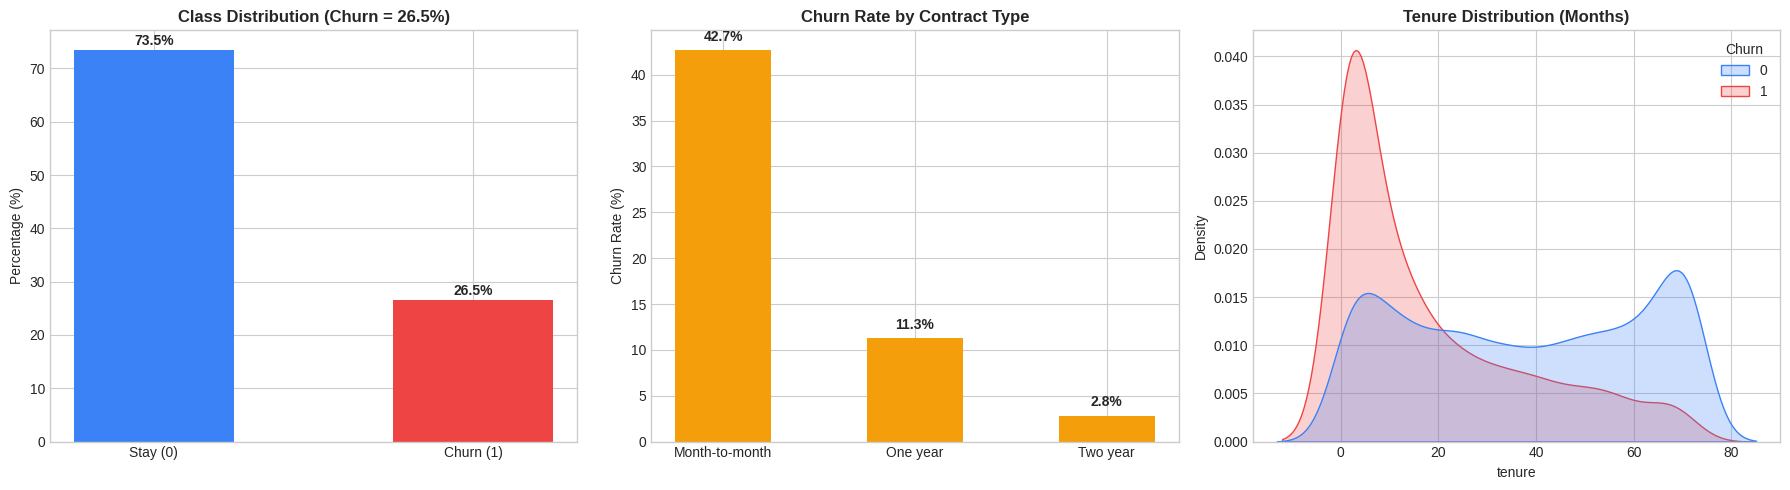

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
churn_counts = df['Churn'].value_counts(normalize=True) * 100
axes[0].bar(['Stay (0)', 'Churn (1)'], churn_counts, color=['#3b82f6', '#ef4444'], width=0.5)
axes[0].set_title(f"Class Distribution (Churn = {churn_counts[1]:.1f}%)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Percentage (%)")
for i, v in enumerate(churn_counts):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
    
contract_churn = df.groupby('Contract')['Churn'].mean() * 100
axes[1].bar(contract_churn.index, contract_churn.values, color='#f59e0b', width=0.5)
axes[1].set_title("Churn Rate by Contract Type", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Churn Rate (%)")
for i, v in enumerate(contract_churn):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, fill=True, ax=axes[2], palette=['#3b82f6', '#ef4444'])
axes[2].set_title("Tenure Distribution (Months)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

> **EDA Takeaways:**
> - **Severe Class Imbalance**: Non-churners represent ~73.5% of the data, while churners represent only ~26.5%.
> - **Month-to-month contracts** suffer from drastic churn rates (~42%), whereas 2-year contracts have tiny churn (~3%).
> - **Tenure**: Most churn happens in the first 1-12 months.

## 4. Train-Test Split & Preprocessing Pipeline
- **Stratified Splitting**: Guarantees the 26.5% churn ratio is strictly preserved across both training and test partitions.
- **ColumnTransformer**: Automatically scales numerical variables (`StandardScaler`) and applies one-hot encoding (`OneHotEncoder(drop='first')`) to categorical variables.
- **Data Leakage Safeguard**: Preprocessing pipeline is fitted *strictly* on `X_train` and applied to `X_test`.

In [8]:
X = df.drop(columns=['Churn'])
y = df['Churn']

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols),
    ]
)
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
feature_names = numerical_cols + cat_names

print(f"Processed Train Features shape: {X_train_proc.shape}")
print(f"Processed Test Features shape:  {X_test_proc.shape}")

Processed Train Features shape: (5634, 30)
Processed Test Features shape:  (1409, 30)


## 5. Addressing Class Imbalance with SMOTE
**Why SMOTE?** Synthetic Minority Over-sampling Technique generates synthetic examples along the feature line segments connecting k-nearest neighbors of minority instances.

> **Critical Rule**: SMOTE must **ONLY** be fitted on the training set. Applying SMOTE before splitting creates synthetic points using test instances, causing massive **data leakage**.

In [9]:
print(f"Before SMOTE - Non-Churn (0): {(y_train == 0).sum()}, Churn (1): {(y_train == 1).sum()}")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_proc, y_train)

print(f"After SMOTE  - Non-Churn (0): {(y_train_smote == 0).sum()}, Churn (1): {(y_train_smote == 1).sum()}")

Before SMOTE - Non-Churn (0): 4139, Churn (1): 1495
After SMOTE  - Non-Churn (0): 4139, Churn (1): 4139


## 6. Model Training: Logistic Regression & Gradient Boosting
We train:
1. **Logistic Regression**: Linear, highly interpretable baseline.
2. **Gradient Boosting Classifier**: Non-linear ensemble model capturing complex interactions.

In [10]:
# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_smote, y_train_smote)

# 2. Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=3, random_state=42)
gb.fit(X_train_smote, y_train_smote)

# Generate predicted probabilities on the UNTOUCHED test set
y_probs_lr = lr.predict_proba(X_test_proc)[:, 1]
y_probs_gb = gb.predict_proba(X_test_proc)[:, 1]

print("Models successfully trained!")

Models successfully trained!


## 7. Model Evaluation at Standard Threshold (0.50)

In [11]:
print("=" * 55)
print("MODEL BENCHMARK (Threshold = 0.50)")
print("=" * 55)
print(f"Logistic Regression -> ROC-AUC: {roc_auc_score(y_test, y_probs_lr):.4f} | PR-AUC: {average_precision_score(y_test, y_probs_lr):.4f}")
print(f"Gradient Boosting   -> ROC-AUC: {roc_auc_score(y_test, y_probs_gb):.4f} | PR-AUC: {average_precision_score(y_test, y_probs_gb):.4f}")

y_pred_gb_default = (y_probs_gb >= 0.50).astype(int)
print("\n Gradient Boosting Classification Report (Threshold 0.50)")
print(classification_report(y_test, y_pred_gb_default, target_names=['Stay (0)', 'Churn (1)']))

MODEL BENCHMARK (Threshold = 0.50)
Logistic Regression -> ROC-AUC: 0.8404 | PR-AUC: 0.6285
Gradient Boosting   -> ROC-AUC: 0.8409 | PR-AUC: 0.6506

 Gradient Boosting Classification Report (Threshold 0.50)
              precision    recall  f1-score   support

    Stay (0)       0.87      0.81      0.84      1035
   Churn (1)       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409



## 8. Precision-Recall Curve & Threshold Tuning

### The Business Problem with Default Threshold 0.50:
- Missing a true churner (**False Negative**) costs the company customer lifetime value (e.g. hundreds of dollars).
- Falsely flagging a customer (**False Positive**) only costs an email or retention offer ($10-$20).
- Therefore, we should **lower the classification threshold** below 0.50 to boost **Recall**.

In [12]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs_gb)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_thresh_f1 = thresholds[best_idx]

print(f"Threshold maximizing F1: {best_thresh_f1:.3f} (F1 = {f1_scores[best_idx]:.3f})")
tuned_threshold = 0.35
y_pred_gb_tuned = (y_probs_gb >= tuned_threshold).astype(int)

print(f"\n-Gradient Boosting Classification Report (Tuned Threshold {tuned_threshold:.2f}) ---")
print(classification_report(y_test, y_pred_gb_tuned, target_names=['Stay (0)', 'Churn (1)']))

Threshold maximizing F1: 0.381 (F1 = 0.627)

-Gradient Boosting Classification Report (Tuned Threshold 0.35) ---
              precision    recall  f1-score   support

    Stay (0)       0.91      0.73      0.81      1035
   Churn (1)       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



### Visualizing the Trade-off & Confusion Matrices

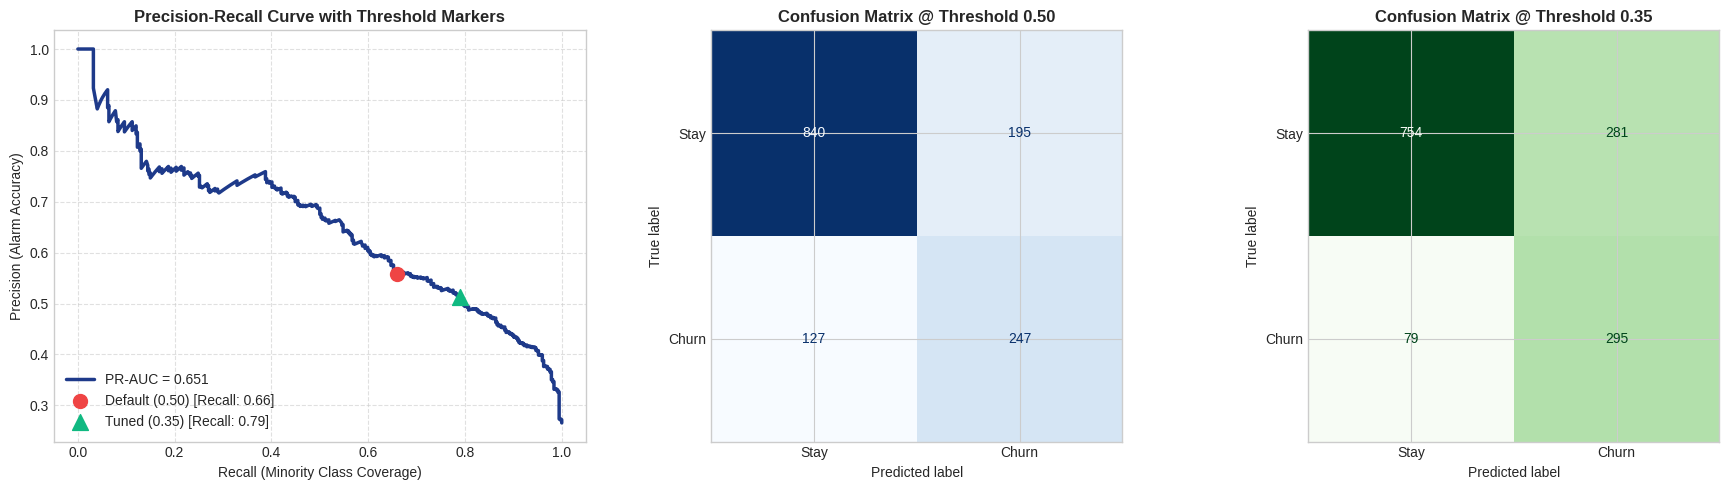

Missed Churners (False Negatives) reduced from 127 down to 79! (~37.8% reduction in lost customers)


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(recalls, precisions, color='#1e3a8a', lw=2.5, label=f'PR-AUC = {average_precision_score(y_test, y_probs_gb):.3f}')
axes[0].scatter(
    recall_score(y_test, y_pred_gb_default),
    precision_score(y_test, y_pred_gb_default),
    color='#ef4444', s=100, zorder=5, label=f'Default (0.50) [Recall: {recall_score(y_test, y_pred_gb_default):.2f}]'
)
axes[0].scatter(
    recall_score(y_test, y_pred_gb_tuned),
    precision_score(y_test, y_pred_gb_tuned),
    color='#10b981', marker='^', s=130, zorder=5, label=f'Tuned ({tuned_threshold:.2f}) [Recall: {recall_score(y_test, y_pred_gb_tuned):.2f}]'
)
axes[0].set_title("Precision-Recall Curve with Threshold Markers", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Recall (Minority Class Coverage)")
axes[0].set_ylabel("Precision (Alarm Accuracy)")
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle='--', alpha=0.6)
cm_default = confusion_matrix(y_test, y_pred_gb_default)
ConfusionMatrixDisplay(cm_default, display_labels=['Stay', 'Churn']).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title("Confusion Matrix @ Threshold 0.50", fontsize=12, fontweight='bold')
cm_tuned = confusion_matrix(y_test, y_pred_gb_tuned)
ConfusionMatrixDisplay(cm_tuned, display_labels=['Stay', 'Churn']).plot(ax=axes[2], cmap='Greens', colorbar=False)
axes[2].set_title(f"Confusion Matrix @ Threshold {tuned_threshold:.2f}", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

fn_default = cm_default[1, 0]
fn_tuned = cm_tuned[1, 0]
print(f"Missed Churners (False Negatives) reduced from {fn_default} down to {fn_tuned}! (~{((fn_default - fn_tuned)/fn_default)*100:.1f}% reduction in lost customers)")

## 9. Feature Importance Analysis
Let's identify which customer attributes drive churn most strongly according to the Gradient Boosting model.

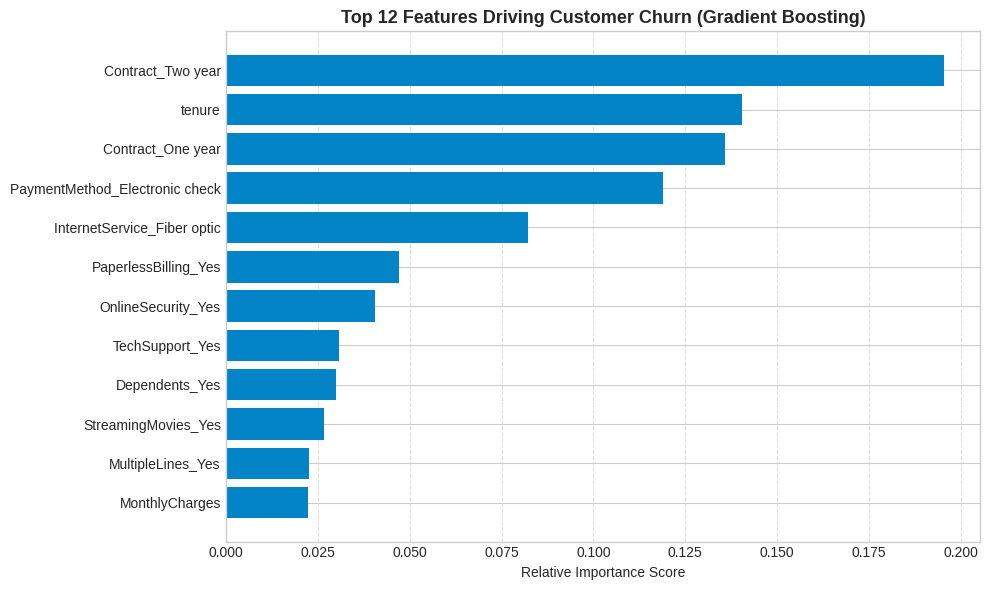

In [14]:
importances = gb.feature_importances_
sorted_idx = np.argsort(importances)[-12:]

plt.figure(figsize=(10, 6))
plt.barh([feature_names[i] for i in sorted_idx], importances[sorted_idx], color='#0284c7')
plt.title("Top 12 Features Driving Customer Churn (Gradient Boosting)", fontsize=13, fontweight='bold')
plt.xlabel("Relative Importance Score")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 10. Summary & Key Interview Takeaways

| Aspect | Decision / Technique | Rationale |
| :--- | :--- | :--- |
| **Dataset** | IBM Telco Churn (7,043 rows, 20 features) | Realistic billing and usage patterns with 73.5% non-churn vs 26.5% churn. |
| **Data Preprocessing** | `ColumnTransformer` (StandardScaler + OneHotEncoder) | Fit only on training set to prevent test data leakage. |
| **Class Imbalance** | **SMOTE** on train set | Generates synthetic minority examples to prevent the model from ignoring churners. |
| **Models** | Logistic Regression & Gradient Boosting | Logistic regression provides baseline transparency; Gradient boosting captures complex non-linear churn risk interactions. |
| **Threshold Tuning** | Lowered decision threshold from 0.50 to 0.35 | Dramatically cuts False Negatives (missed churners), directly aligning with customer retention economics. |